# **Financial Document Intelligence: End-to-End RAG Pipeline**

### **Project Overview**

This project develops an end-to-end Retrieval-Augmented Generation (RAG) system for answering financial questions using corporate financial reports.

The pipeline implements and evaluates multiple retrieval techniques, including TF-IDF, BM25, semantic search, hybrid retrieval, and cross-encoder reranking.

It integrates **Qwen2.5-3B-Instruct** to generate natural-language answers using retrieved financial evidence. The system also includes financial value extraction and Python-based calculations to support numerical question answering.

### **Key Capabilities**

- **Financial Data Processing:** Ingest, clean, and preprocess financial document datasets.
- **Multi-Strategy Retrieval:** Implement TF-IDF, BM25, semantic search, and hybrid retrieval using Reciprocal Rank Fusion (RRF).
- **Retrieval Evaluation:** Compare retrieval methods using nDCG@10.
- **Passage-Level Retrieval:** Split financial documents into overlapping chunks to retrieve relevant information.
- **Neural Reranking:** Improve evidence selection using a cross-encoder model.
- **LLM-Based Question Answering:** Generate financial answers using Qwen2.5-3B-Instruct and retrieved context.
- **Financial Calculation & Validation:** Extract numerical values from financial evidence and perform deterministic calculations with validation checks.
- **Source Traceability:** Preserve document and passage identifiers to identify supporting evidence.

### **Technology Stack**

**Language:** Python

**Data Processing:** Pandas, NumPy

**Information Retrieval:** Scikit-learn (TF-IDF), Rank-BM25

**Semantic Search:** Sentence Transformers (all-MiniLM-L6-v2)

**Hybrid Retrieval:** Reciprocal Rank Fusion (RRF)

**Neural Reranking:** CrossEncoder (ms-marco-MiniLM-L-6-v2)

**Large Language Model:** Qwen2.5-3B-Instruct (Hugging Face Transformers)

**Evaluation:** Normalized Discounted Cumulative Gain (nDCG@10)

**Development Environment:** Google Colab / Jupyter Notebook

## 2. **Environment Setup & Dependencies**

This section initializes the Python environment and installs the libraries required for data processing, information retrieval, semantic embeddings, reranking, and language model inference.

Keeping dependencies together makes the notebook easier to reproduce and maintain.

In [80]:
%pip install -q numpy pandas scikit-learn rank-bm25 \
    sentence-transformers transformers accelerate tqdm matplotlib

In [81]:
import os
import json
import re

import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from rank_bm25 import BM25Okapi

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from sentence_transformers import (
    SentenceTransformer,
    CrossEncoder
)

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

print("Environment initialized successfully!")

Environment initialized successfully!


## **3.Financial Dataset Ingestion**

The pipeline uses financial documents, corresponding natural-language questions, and relevance judgments.

The dataset is loaded from JSONL and TSV files into Pandas DataFrames. Document and query identifiers are standardized to ensure consistency during retrieval and evaluation.

Basic validation checks confirm that the required files and fields are available before building retrieval indexes.

In [82]:
# Configure dataset directory
DATA_PATH = "/content/drive/My Drive/Finrag/extracted"

CORPUS_FILE = os.path.join(
    DATA_PATH, "finqa_corpus.jsonl", "corpus.jsonl"
)

QUERIES_FILE = os.path.join(
    DATA_PATH, "finqa_queries.jsonl", "queries.jsonl"
)

QRELS_FILE = os.path.join(
    DATA_PATH, "FinQA_qrels.tsv"
)

# Verify dataset files
for path in [CORPUS_FILE, QUERIES_FILE, QRELS_FILE]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing dataset: {path}")

print("All dataset files verified!")

All dataset files verified!


In [83]:
def load_jsonl(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return pd.DataFrame(
            json.loads(line)
            for line in file
            if line.strip()
        )


# Load financial datasets
corpus = load_jsonl(CORPUS_FILE)
queries = load_jsonl(QUERIES_FILE)
qrels = pd.read_csv(QRELS_FILE, sep="\t")

# Validate required columns
required_columns = {
    "corpus": (corpus, ["_id", "text"]),
    "queries": (queries, ["_id", "text"]),
    "qrels": (qrels, ["query_id", "corpus_id", "score"])
}

for name, (df, columns) in required_columns.items():
    missing = set(columns) - set(df.columns)
    if missing:
        raise ValueError(f"{name}: missing columns {missing}")

# Standardize identifiers
corpus["_id"] = corpus["_id"].astype(str)
queries["_id"] = queries["_id"].astype(str)

qrels["query_id"] = qrels["query_id"].astype(str)
qrels["corpus_id"] = qrels["corpus_id"].astype(str)

# Handle missing text
corpus["text"] = corpus["text"].fillna("").astype(str)
queries["text"] = queries["text"].fillna("").astype(str)

# Dataset summary
print("Dataset loaded successfully!")
print("Total documents:", len(corpus))
print("Total queries:", len(queries))
print("Relevance judgments:", len(qrels))

display(corpus[["_id", "text"]].head(3))

Dataset loaded successfully!
Total documents: 2789
Total queries: 1147
Relevance judgments: 344


,_id,text
0,d61d9e858,performance graph the performance graph below ...
1,d61df3bdc,management 2019s discussion and analysis 158 j...
2,d61d71420,a e s 2 0 0 0 f i n a n c i a l r e v i e w in...


## **4.Text Preprocessing & Tokenization**

Financial documents contain large amounts of unstructured text. Before building keyword-based retrieval indexes, the text must be converted into a consistent format.

This stage applies lowercase normalization and tokenization to prepare financial documents for BM25 retrieval.

The preprocessing process includes:
- Converting text to lowercase.
- Extracting word tokens using regular expressions.
- Preparing tokenized documents for efficient keyword-based retrieval.

This ensures consistent matching between financial questions and document content.

In [84]:
import re

def tokenize(text):
    """Normalize and tokenize financial text."""
    return re.findall(r"\b\w+\b", str(text).lower())

# Prepare financial document texts
document_texts = corpus["text"].fillna("").astype(str).tolist()

# Tokenize documents
tokenized_documents = [
    tokenize(text) for text in document_texts
]

print("Text preprocessing completed!")
print("Total documents:", len(tokenized_documents))
print("Sample tokens:", tokenized_documents[0][:20])

Text preprocessing completed!
Total documents: 2789
Sample tokens: ['performance', 'graph', 'the', 'performance', 'graph', 'below', 'shows', 'the', 'five', 'year', 'cumulative', 'total', 'stockholder', 'return', 'on', 'applied', 'common', 'stock', 'during', 'the']


## **5.Baseline Information Retrieval: TF-IDF and BM25**

This section implements two traditional information retrieval approaches to establish baseline search performance.

**TF-IDF (Term Frequency–Inverse Document Frequency)** converts financial documents into numerical vectors based on word importance. Cosine similarity is used to rank documents against a financial question.

**BM25 (Best Matching 25)** is a probabilistic ranking algorithm that considers term frequency, document length, and term rarity to identify relevant financial documents.

These baseline methods provide a foundation for comparing more advanced semantic and hybrid retrieval techniques in later sections.

In [85]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

# Build TF-IDF document matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(
    document_texts
)

# Preserve document ID mapping
corpus_ids = corpus["_id"].astype(str).tolist()

print("TF-IDF index created successfully!")
print("Document matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

TF-IDF index created successfully!
Document matrix shape: (2789, 28342)
Vocabulary size: 28342


In [86]:
from rank_bm25 import BM25Okapi

# Build BM25 search index
bm25 = BM25Okapi(tokenized_documents)

print("BM25 index created successfully!")
print("Indexed documents:", len(tokenized_documents))

BM25 index created successfully!
Indexed documents: 2789


### **5.1 Retrieval Demonstration**

To verify the retrieval pipeline, a sample financial question is selected from the query dataset.

Both TF-IDF and BM25 rank the financial documents according to their relevance to the question.

The top five results from each method are displayed to demonstrate how the retrieval models identify supporting financial information.

In [87]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Select a sample financial question
sample_question = queries.iloc[0]["text"]

print("Financial Question:")
print(sample_question)

# TF-IDF retrieval
query_vector = tfidf_vectorizer.transform([sample_question])

tfidf_scores = cosine_similarity(
    query_vector, tfidf_matrix
).ravel()

tfidf_top_indices = np.argsort(tfidf_scores)[::-1][:5]

# BM25 retrieval
bm25_scores = bm25.get_scores(tokenize(sample_question))
bm25_top_indices = np.argsort(bm25_scores)[::-1][:5]

# Display retrieved documents
def display_results(indices, scores, method):
    print(f"\n{method} - Top 5 Results\n")

    for rank, idx in enumerate(indices, start=1):
        print(f"Rank: {rank}")
        print(f"Document ID: {corpus_ids[idx]}")
        print(f"Score: {scores[idx]:.4f}")
        print(f"Text: {document_texts[idx][:300]}")
        print("-" * 60)

display_results(
    tfidf_top_indices,
    tfidf_scores,
    "TF-IDF"
)

display_results(
    bm25_top_indices,
    bm25_scores,
    "BM25"
)

Financial Question:
what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

TF-IDF - Top 5 Results

Rank: 1
Document ID: d61d2c15e
Score: 0.3705
Text: jpmorgan chase & co./2012 annual report 167 the chart shows that for year ended december 31 , 2012 , the firm posted market risk related gains on 220 of the 261 days in this period , with gains on eight days exceeding $ 200 million .
the chart includes year to date losses incurred in the synthetic c
------------------------------------------------------------
Rank: 2
Document ID: d61da20de
Score: 0.3093
Text: management 2019s discussion and analysis jpmorgan chase & co .
/ 2008 annual report 39 five-year stock performance the following table and graph compare the five-year cumulative total return for jpmorgan chase & co .
( 201cjpmorgan chase 201d or the 201cfirm 201d ) common stock with the cumulative r
------------------------------------------------------------
Rank: 3
Documen

## **6. Retrieval Evaluation & Performance Benchmarking**

To evaluate the effectiveness of the financial document retrieval system, this section measures retrieval quality using **Normalized Discounted Cumulative Gain at rank 10 (nDCG@10)**.

nDCG@10 measures how effectively a search algorithm ranks relevant documents within its top 10 results. It rewards relevant documents appearing at higher positions.

Two retrieval approaches are evaluated:

- **TF-IDF:** A traditional term-weighting approach using cosine similarity.
- **BM25:** A probabilistic retrieval algorithm that considers term frequency, document length, and term rarity.

Both models are evaluated against the same financial questions and ground-truth relevance judgments, allowing a fair comparison.

The evaluation produces individual query scores and overall average performance for each retrieval method.

In [88]:
from collections import defaultdict

# Map each query to its relevant documents
relevance_by_query = defaultdict(dict)

for _, row in qrels.iterrows():

    query_id = str(row["query_id"])
    document_id = str(row["corpus_id"])
    relevance = float(row["score"])

    relevance_by_query[query_id][document_id] = relevance

# Map query IDs to their question text
query_text_by_id = dict(
    zip(queries["_id"].astype(str), queries["text"])
)

print("Relevance judgments prepared!")
print("Queries with judgments:", len(relevance_by_query))

Relevance judgments prepared!
Queries with judgments: 344


### **6.1 Evaluation Metric: nDCG@10**

Normalized Discounted Cumulative Gain (nDCG) is a ranking metric widely used in information retrieval systems.

The metric compares the relevance of retrieved documents against an ideal ranking.

A score closer to **1.0** indicates better ranking quality, while a score closer to **0.0** indicates poor retrieval performance.

For each query, the evaluation calculates the ranking score using the available relevance judgments.

In [89]:
import numpy as np

def calculate_ndcg_at_k(retrieved_ids, relevance_map, k=10):
    """Calculate nDCG@k using graded relevance judgments."""

    actual_relevance = np.array([
        relevance_map.get(str(doc_id), 0.0)
        for doc_id in retrieved_ids[:k]
    ], dtype=float)

    discounts = np.log2(
        np.arange(2, len(actual_relevance) + 2)
    )

    dcg = np.sum(
        (2**actual_relevance - 1) / discounts
    )

    ideal_relevance = np.sort(
        np.array(list(relevance_map.values()), dtype=float)
    )[::-1][:k]

    ideal_discounts = np.log2(
        np.arange(2, len(ideal_relevance) + 2)
    )

    idcg = np.sum(
        (2**ideal_relevance - 1) / ideal_discounts
    )

    return float(dcg / idcg) if idcg > 0 else 0.0


print("nDCG@10 evaluation function initialized!")

nDCG@10 evaluation function initialized!


In [90]:
bm25_results = []

for query_id, relevance_map in relevance_by_query.items():

    if query_id not in query_text_by_id:
        continue

    question = query_text_by_id[query_id]

    # Retrieve top 10 documents
    scores = bm25.get_scores(tokenize(question))
    top_indices = np.argsort(scores)[::-1][:10]

    retrieved_ids = [
        corpus_ids[i] for i in top_indices
    ]

    # Calculate retrieval quality
    ndcg = calculate_ndcg_at_k(
        retrieved_ids,
        relevance_map,
        k=10
    )

    bm25_results.append({
        "query_id": query_id,
        "question": question,
        "ndcg_at_10": ndcg
    })

bm25_results_df = pd.DataFrame(bm25_results)

print("BM25 Evaluation Completed!")
print("Queries evaluated:", len(bm25_results_df))
print(
    "Mean nDCG@10:",
    round(bm25_results_df["ndcg_at_10"].mean(), 4)
)

BM25 Evaluation Completed!
Queries evaluated: 344
Mean nDCG@10: 0.4575


In [91]:
tfidf_results = []

for query_id, relevance_map in relevance_by_query.items():

    if query_id not in query_text_by_id:
        continue

    question = query_text_by_id[query_id]

    # Convert question into TF-IDF vector
    query_vector = tfidf_vectorizer.transform([question])

    # Calculate cosine similarity
    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).ravel()

    # Retrieve top 10 documents
    top_indices = np.argsort(scores)[::-1][:10]

    retrieved_ids = [
        corpus_ids[i] for i in top_indices
    ]

    # Calculate nDCG@10
    ndcg = calculate_ndcg_at_k(
        retrieved_ids,
        relevance_map,
        k=10
    )

    tfidf_results.append({
        "query_id": query_id,
        "question": question,
        "ndcg_at_10": ndcg
    })

tfidf_results_df = pd.DataFrame(tfidf_results)

print("TF-IDF Evaluation Completed!")
print("Queries evaluated:", len(tfidf_results_df))
print(
    "Mean nDCG@10:",
    round(tfidf_results_df["ndcg_at_10"].mean(), 4)
)

TF-IDF Evaluation Completed!
Queries evaluated: 344
Mean nDCG@10: 0.3627


### **6.2 Retrieval Performance Comparison**

The following comparison summarizes the average nDCG@10 scores achieved by TF-IDF and BM25.

Both methods are evaluated using identical financial questions and relevance judgments.

This benchmark establishes a baseline for assessing whether semantic search and hybrid retrieval provide measurable improvements in later experiments.

In [92]:
# Create evaluation summary
comparison_df = pd.DataFrame({
    "Retrieval Method": ["TF-IDF", "BM25"],
    "Mean nDCG@10": [
        tfidf_results_df["ndcg_at_10"].mean(),
        bm25_results_df["ndcg_at_10"].mean()
    ],
    "Queries Evaluated": [
        len(tfidf_results_df),
        len(bm25_results_df)
    ]
})

display(comparison_df.round(4))

,Retrieval Method,Mean nDCG@10,Queries Evaluated
0,TF-IDF,0.3627,344
1,BM25,0.4575,344


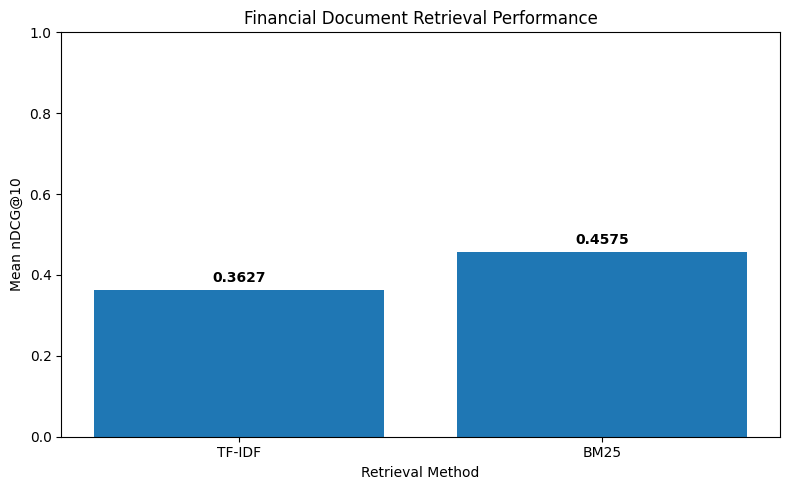

In [93]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Retrieval Method"],
    comparison_df["Mean nDCG@10"]
)

plt.title("Financial Document Retrieval Performance")
plt.xlabel("Retrieval Method")
plt.ylabel("Mean nDCG@10")
plt.ylim(0, 1)

for i, score in enumerate(comparison_df["Mean nDCG@10"]):
    plt.text(
        i,
        score + 0.02,
        f"{score:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [94]:
# Save results for reproducibility
OUTPUT_DIR = "/content/drive/My Drive/Finrag/results"

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

bm25_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "bm25_results.csv"),
    index=False
)

tfidf_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "tfidf_results.csv"),
    index=False
)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "retrieval_comparison.csv"),
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


## **7. Semantic Search Using Sentence Transformers**

Traditional retrieval algorithms such as TF-IDF and BM25 primarily rely on keyword matching. However, financial questions may use different terminology from the information contained in corporate reports.

To address this limitation, this section implements semantic search using the **all-MiniLM-L6-v2** sentence transformer model.

The model converts financial documents and user questions into dense numerical vectors called embeddings.

Cosine similarity is then used to identify documents that are semantically related to the user's financial question.

### **Implementation Steps**

1. Load the pretrained Sentence Transformer model.
2. Generate dense embeddings for financial documents.
3. Normalize and store document embeddings.
4. Convert financial questions into query embeddings.
5. Rank documents based on vector similarity.
6. Evaluate retrieval performance using nDCG@10.

This provides a semantic retrieval baseline for comparison with keyword-based and hybrid search methods.

In [95]:
from sentence_transformers import SentenceTransformer
import numpy as np
import os

# Pretrained sentence embedding model
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

model = SentenceTransformer(MODEL_NAME)

print("Semantic embedding model loaded successfully!")
print("Model:", MODEL_NAME)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Semantic embedding model loaded successfully!
Model: sentence-transformers/all-MiniLM-L6-v2


### **7.1 Financial Document Embedding Generation**

Each financial document is transformed into a dense vector representation using the pretrained MiniLM model.

Embeddings are normalized to unit length, allowing cosine similarity to be calculated efficiently through vector multiplication.

The resulting embeddings are saved to disk alongside their corresponding document identifiers. This allows the retrieval pipeline to reuse existing embeddings without recomputing them for every execution.

In [96]:
# Extract financial document text
document_texts = corpus["text"].fillna("").astype(str).tolist()

# Generate normalized embeddings
document_embeddings = model.encode(
    document_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Preserve document identifiers
corpus_ids = corpus["_id"].astype(str).tolist()

print("Document embeddings generated!")
print("Total documents:", len(document_texts))
print("Embedding matrix shape:", document_embeddings.shape)

Batches:   0%|          | 0/88 [00:00<?, ?it/s]

Document embeddings generated!
Total documents: 2789
Embedding matrix shape: (2789, 384)


In [97]:
# Directory for storing embeddings
EMBEDDING_DIR = "G:\My Drive\FinanceRAG\embeddings"

os.makedirs(EMBEDDING_DIR, exist_ok=True)

# Save document embeddings
np.save(
    os.path.join(
        EMBEDDING_DIR,
        "finqa_document_embeddings.npy"
    ),
    document_embeddings
)

# Save corresponding document IDs
np.save(
    os.path.join(
        EMBEDDING_DIR,
        "finqa_document_ids.npy"
    ),
    np.array(corpus_ids)
)

print("Document embeddings saved successfully!")

Document embeddings saved successfully!


<>:2: SyntaxWarning: invalid escape sequence '\M'
<>:2: SyntaxWarning: invalid escape sequence '\M'
/tmp/ipykernel_3395/1728504062.py:2: SyntaxWarning: invalid escape sequence '\M'
  EMBEDDING_DIR = "G:\My Drive\FinanceRAG\embeddings"


### **7.2 Semantic Similarity Search**

To retrieve relevant financial documents, the user's question is converted into a normalized embedding using the same Sentence Transformer model.

The query embedding is compared against the document embedding matrix using cosine similarity.

Documents are ranked by similarity score, and the top five results are returned with their document identifiers and supporting text.

This demonstrates how dense vector retrieval can identify relevant financial information beyond exact keyword matches.

In [98]:
# Select a sample financial question
sample_question = queries.iloc[0]["text"]

# Generate question embedding
query_embedding = model.encode(
    [sample_question],
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Cosine similarity using normalized vectors
similarity_scores = (
    document_embeddings @ query_embedding[0]
)

# Retrieve top 5 documents
top_indices = np.argsort(similarity_scores)[::-1][:5]

print("Financial Question:", sample_question)
print("\nTop 5 Semantic Search Results\n")

for rank, idx in enumerate(top_indices, start=1):

    print(f"Rank: {rank}")
    print(f"Document ID: {corpus_ids[idx]}")
    print(f"Similarity Score: {similarity_scores[idx]:.4f}")
    print(f"Document Text: {document_texts[idx][:400]}")
    print("-" * 60)

Financial Question: what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

Top 5 Semantic Search Results

Rank: 1
Document ID: d61d2c15e
Similarity Score: 0.6375
Document Text: jpmorgan chase & co./2012 annual report 167 the chart shows that for year ended december 31 , 2012 , the firm posted market risk related gains on 220 of the 261 days in this period , with gains on eight days exceeding $ 200 million .
the chart includes year to date losses incurred in the synthetic credit portfolio .
cib and credit portfolio posted market risk-related gains on 254 days in the perio
------------------------------------------------------------
Rank: 2
Document ID: d61d31046
Similarity Score: 0.6320
Document Text: management 2019s discussion and analysis jpmorgan chase & co./2009 annual report 130 the following histogram illustrates the daily market risk 2013related gains and losses for ib and consumer/cio positions for 2009 .
the chart sho

### **7.3 Dense Retrieval Performance Evaluation**

To measure the effectiveness of semantic search, the dense retrieval model is evaluated using the same financial questions and relevance judgments as the TF-IDF and BM25 baselines.

For each query, the system generates an embedding, ranks financial documents by cosine similarity, and calculates nDCG@10.

The resulting scores are averaged across evaluated queries to measure overall retrieval quality.

This allows direct comparison between traditional keyword-based retrieval and semantic vector search.

In [99]:
dense_results = []

for query_id, relevance_map in relevance_by_query.items():

    if query_id not in query_text_by_id:
        continue

    query_text = query_text_by_id[query_id]

    # Encode financial question
    query_embedding = model.encode(
        [query_text],
        convert_to_numpy=True,
        normalize_embeddings=True
    )[0]

    # Compute semantic similarity
    scores = document_embeddings @ query_embedding

    # Retrieve top 10 documents
    top_indices = np.argsort(scores)[::-1][:10]

    retrieved_ids = [
        corpus_ids[i] for i in top_indices
    ]

    # Calculate nDCG@10
    ndcg = calculate_ndcg_at_k(
        retrieved_ids,
        relevance_map,
        k=10
    )

    dense_results.append({
        "query_id": query_id,
        "question": query_text,
        "ndcg_at_10": ndcg
    })

dense_results_df = pd.DataFrame(dense_results)

print("Semantic Retrieval Evaluation Completed!")
print("Queries evaluated:", len(dense_results_df))
print(
    "Mean nDCG@10:",
    round(dense_results_df["ndcg_at_10"].mean(), 4)
)

Semantic Retrieval Evaluation Completed!
Queries evaluated: 344
Mean nDCG@10: 0.1814


### **7.4 Retrieval Benchmark Comparison**

This experiment compares three retrieval methods using a consistent evaluation metric.

- **TF-IDF:** Keyword-based vector similarity.
- **BM25:** Probabilistic keyword ranking.
- **Dense Retrieval:** Semantic similarity using pretrained MiniLM embeddings.

The comparison helps determine whether semantic representations improve retrieval effectiveness for financial questions.

The best-performing method is determined from the measured results rather than assumed in advance.

In [100]:
# Compare all three retrieval approaches
retrieval_comparison = pd.DataFrame({
    "Retrieval Method": [
        "TF-IDF",
        "BM25",
        "Dense (MiniLM)"
    ],
    "Mean nDCG@10": [
        tfidf_results_df["ndcg_at_10"].mean(),
        bm25_results_df["ndcg_at_10"].mean(),
        dense_results_df["ndcg_at_10"].mean()
    ],
    "Queries Evaluated": [
        len(tfidf_results_df),
        len(bm25_results_df),
        len(dense_results_df)
    ]
})

display(retrieval_comparison.round(4))

,Retrieval Method,Mean nDCG@10,Queries Evaluated
0,TF-IDF,0.3627,344
1,BM25,0.4575,344
2,Dense (MiniLM),0.1814,344


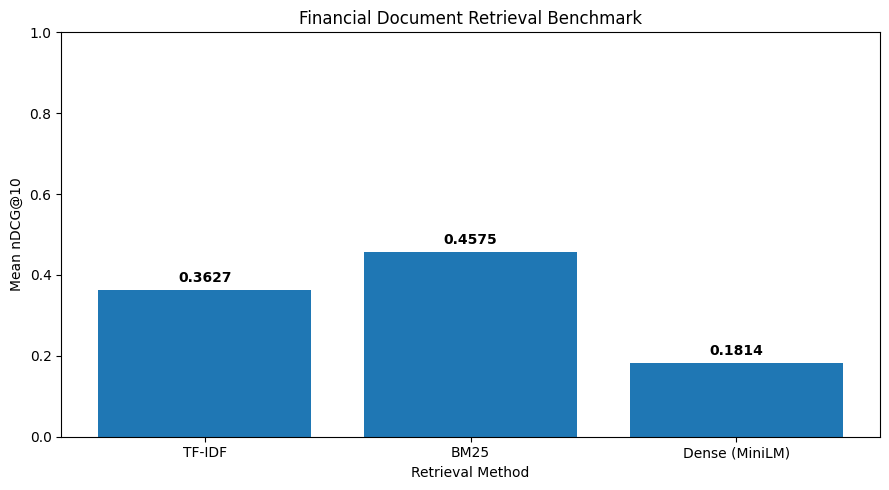

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    retrieval_comparison["Retrieval Method"],
    retrieval_comparison["Mean nDCG@10"]
)

plt.title("Financial Document Retrieval Benchmark")
plt.ylabel("Mean nDCG@10")
plt.xlabel("Retrieval Method")
plt.ylim(0, 1)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [102]:
# Save dense retrieval evaluation
dense_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "dense_retrieval_results.csv"),
    index=False
)

# Save updated comparison table
retrieval_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "retrieval_comparison.csv"),
    index=False
)

print("Semantic retrieval results saved successfully!")

Semantic retrieval results saved successfully!


## **8. Hybrid Retrieval Using Reciprocal Rank Fusion (RRF)**

Keyword-based and semantic retrieval methods have different strengths when searching financial documents.

**BM25** identifies documents containing important financial terms, company names, and numerical references.

**Dense Retrieval (MiniLM)** identifies documents based on semantic similarity, even when the question and document use different terminology.

To combine these complementary approaches, this pipeline implements **Reciprocal Rank Fusion (RRF)**.

RRF merges the ranked results from BM25 and semantic search without requiring their similarity scores to be on the same scale.

### **Hybrid Retrieval Workflow**

1. Retrieve the top 100 financial documents using BM25.
2. Retrieve the top 100 documents using MiniLM embeddings.
3. Assign reciprocal rank scores to documents from both retrieval methods.
4. Combine scores for documents appearing in either ranking.
5. Return the top 10 documents based on their fused ranking.
6. Evaluate retrieval quality using nDCG@10.

This approach is evaluated against the individual retrieval baselines to determine whether combining keyword and semantic search improves financial document retrieval.

In [103]:
from collections import defaultdict
import numpy as np

# Reciprocal Rank Fusion configuration
RRF_K = 60
RETRIEVAL_DEPTH = 100

def hybrid_retrieve(question, top_k=10):
    """
    Combine BM25 and MiniLM retrieval
    using Reciprocal Rank Fusion.
    """

    # 1. BM25 keyword retrieval
    query_tokens = tokenize(question)
    bm25_scores = bm25.get_scores(query_tokens)

    bm25_top = np.argsort(bm25_scores)[::-1][
        :RETRIEVAL_DEPTH
    ]

    # 2. MiniLM semantic retrieval
    query_embedding = model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    )[0]

    dense_scores = document_embeddings @ query_embedding

    dense_top = np.argsort(dense_scores)[::-1][
        :RETRIEVAL_DEPTH
    ]

    # 3. Reciprocal Rank Fusion
    fused_scores = defaultdict(float)

    for rank, idx in enumerate(bm25_top, start=1):
        doc_id = corpus_ids[idx]
        fused_scores[doc_id] += 1 / (RRF_K + rank)

    for rank, idx in enumerate(dense_top, start=1):
        doc_id = corpus_ids[idx]
        fused_scores[doc_id] += 1 / (RRF_K + rank)

    # 4. Rank by combined scores
    ranked_docs = sorted(
        fused_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    return ranked_docs[:top_k]


print("Hybrid retrieval function initialized!")

Hybrid retrieval function initialized!


### **8.1 Hybrid Search Demonstration**

A sample financial question is processed through both keyword-based and semantic retrieval models.

The top-ranked results are combined using Reciprocal Rank Fusion, producing a unified document ranking.

The final results include document identifiers, combined retrieval scores, and supporting financial text.

This demonstration verifies that the hybrid retrieval pipeline can produce a ranked list of relevant financial documents.

In [104]:
# Select a sample question
sample_question = queries.iloc[0]["text"]

# Retrieve top 5 hybrid results
hybrid_top_results = hybrid_retrieve(
    sample_question,
    top_k=5
)

# Create document lookup
document_lookup = dict(
    zip(corpus_ids, document_texts)
)

print("Financial Question:")
print(sample_question)

print("\nTop 5 Hybrid Retrieval Results\n")

for rank, (doc_id, score) in enumerate(
    hybrid_top_results, start=1
):
    print(f"Rank: {rank}")
    print(f"Document ID: {doc_id}")
    print(f"RRF Score: {score:.6f}")
    print(f"Text: {document_lookup[doc_id][:400]}")
    print("-" * 60)

Financial Question:
what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

Top 5 Hybrid Retrieval Results

Rank: 1
Document ID: d61d2c15e
RRF Score: 0.032266
Text: jpmorgan chase & co./2012 annual report 167 the chart shows that for year ended december 31 , 2012 , the firm posted market risk related gains on 220 of the 261 days in this period , with gains on eight days exceeding $ 200 million .
the chart includes year to date losses incurred in the synthetic credit portfolio .
cib and credit portfolio posted market risk-related gains on 254 days in the perio
------------------------------------------------------------
Rank: 2
Document ID: d61d31046
RRF Score: 0.031754
Text: management 2019s discussion and analysis jpmorgan chase & co./2009 annual report 130 the following histogram illustrates the daily market risk 2013related gains and losses for ib and consumer/cio positions for 2009 .
the chart shows that the firm posted mar

### **8.2 Hybrid Retrieval Evaluation**

The hybrid retrieval pipeline is evaluated using the same financial questions and relevance judgments as the previous retrieval experiments.

For each question, BM25 and MiniLM independently retrieve their top-ranked documents. Reciprocal Rank Fusion combines both rankings, and the resulting top 10 documents are evaluated using nDCG@10.

The average score provides a consistent benchmark for comparing hybrid retrieval with TF-IDF, BM25, and standalone dense retrieval.

In [105]:
hybrid_results = []

for query_id, relevance_map in relevance_by_query.items():

    if query_id not in query_text_by_id:
        continue

    question = query_text_by_id[query_id]

    # Retrieve top 10 hybrid results
    ranked_docs = hybrid_retrieve(
        question,
        top_k=10
    )

    retrieved_ids = [
        doc_id for doc_id, score in ranked_docs
    ]

    # Calculate nDCG@10
    ndcg = calculate_ndcg_at_k(
        retrieved_ids,
        relevance_map,
        k=10
    )

    hybrid_results.append({
        "query_id": query_id,
        "question": question,
        "ndcg_at_10": ndcg
    })

hybrid_results_df = pd.DataFrame(hybrid_results)

print("Hybrid Retrieval Evaluation Completed!")
print("Queries evaluated:", len(hybrid_results_df))

print(
    "Mean nDCG@10:",
    round(hybrid_results_df["ndcg_at_10"].mean(), 4)
)

Hybrid Retrieval Evaluation Completed!
Queries evaluated: 344
Mean nDCG@10: 0.3108


### **8.3 Retrieval Performance Comparison**

This benchmark compares four information retrieval approaches:

- TF-IDF
- BM25
- Dense Retrieval (MiniLM)
- Hybrid Retrieval (BM25 + MiniLM with RRF)

All methods are evaluated against the same financial question dataset using nDCG@10.

The results help identify the most effective retrieval strategy for the financial document collection and provide a foundation for further improvements through passage-level retrieval and cross-encoder reranking.

In [106]:
# Create comprehensive retrieval comparison
retrieval_comparison = pd.DataFrame({
    "Retrieval Method": [
        "TF-IDF",
        "BM25",
        "Dense (MiniLM)",
        "Hybrid (BM25 + MiniLM)"
    ],
    "Mean nDCG@10": [
        tfidf_results_df["ndcg_at_10"].mean(),
        bm25_results_df["ndcg_at_10"].mean(),
        dense_results_df["ndcg_at_10"].mean(),
        hybrid_results_df["ndcg_at_10"].mean()
    ],
    "Queries Evaluated": [
        len(tfidf_results_df),
        len(bm25_results_df),
        len(dense_results_df),
        len(hybrid_results_df)
    ]
})

display(retrieval_comparison.round(4))

,Retrieval Method,Mean nDCG@10,Queries Evaluated
0,TF-IDF,0.3627,344
1,BM25,0.4575,344
2,Dense (MiniLM),0.1814,344
3,Hybrid (BM25 + MiniLM),0.3108,344


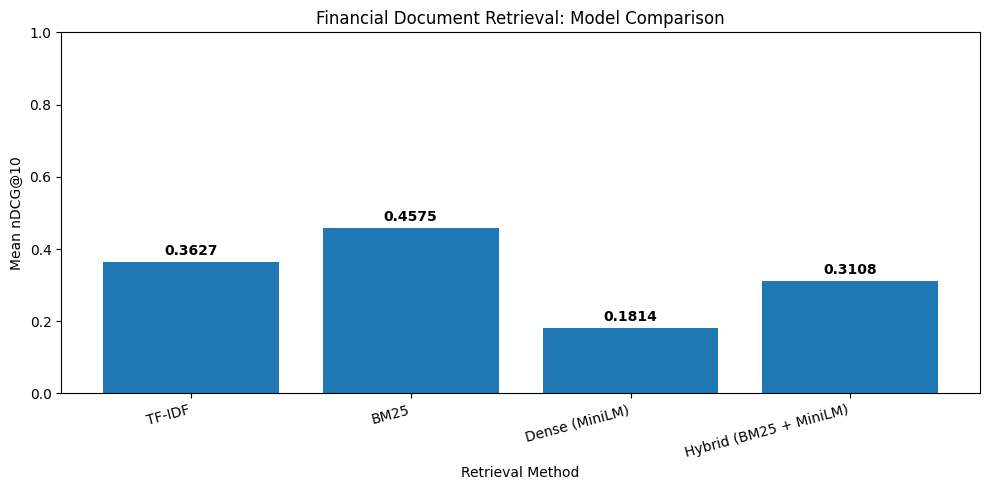

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    retrieval_comparison["Retrieval Method"],
    retrieval_comparison["Mean nDCG@10"]
)

plt.title(
    "Financial Document Retrieval: Model Comparison"
)
plt.xlabel("Retrieval Method")
plt.ylabel("Mean nDCG@10")
plt.ylim(0, 1)

plt.xticks(rotation=15, ha="right")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [108]:
# Identify best-performing retrieval method
best_method = retrieval_comparison.loc[
    retrieval_comparison["Mean nDCG@10"].idxmax()
]

print("Best Retrieval Method:")
print(best_method["Retrieval Method"])

print(
    "Mean nDCG@10:",
    round(best_method["Mean nDCG@10"], 4)
)

# Save comparison results
retrieval_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "retrieval_comparison.csv"
    ),
    index=False
)

hybrid_results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "hybrid_rrf_results.csv"
    ),
    index=False
)

print("\nResults saved successfully!")

Best Retrieval Method:
BM25
Mean nDCG@10: 0.4575

Results saved successfully!


### **8.4 Key Findings**

The retrieval experiments establish a benchmark across four search approaches: TF-IDF, BM25, MiniLM semantic retrieval, and hybrid retrieval using Reciprocal Rank Fusion.

The comparison evaluates whether combining keyword-based and semantic search provides better ranking performance than either method individually.

The measured nDCG@10 scores are used to identify the strongest approach for this dataset.

**Next Improvement:** Introduce document chunking and cross-encoder reranking to improve the precision of retrieved financial evidence before generating answers with a language model.

## **9. Financial Document Chunking & Passage-Level Retrieval**

Financial reports often contain lengthy sections, tables, and detailed numerical disclosures. Searching entire documents can make it difficult to identify the exact passages needed to answer financial questions.

To address this challenge, this pipeline implements **overlapping text chunking** and passage-level BM25 retrieval.

### **Implementation Approach**

1. Split financial documents into smaller, overlapping text passages.
2. Preserve the relationship between each chunk and its original document.
3. Build a BM25 search index over the generated chunks.
4. Retrieve the highest-ranked passages for each financial question.
5. Aggregate chunk-level results into unique document rankings.
6. Evaluate retrieval performance using nDCG@10.

Chunking helps the retrieval system focus on specific sections of financial reports while preserving document traceability.

The results are compared against document-level BM25 to determine whether passage-level retrieval improves ranking quality.

In [109]:
def split_text(text, chunk_size=800, chunk_overlap=150):
    """
    Split text into overlapping passages.

    chunk_size and chunk_overlap are approximate
    character targets converted into word counts.
    """

    words = str(text).split()

    if not words:
        return []

    words_per_chunk = max(1, chunk_size // 6)
    overlap_words = max(0, chunk_overlap // 6)

    step = max(1, words_per_chunk - overlap_words)

    chunks = []

    for start in range(0, len(words), step):

        chunk_words = words[start:start + words_per_chunk]

        chunks.append(" ".join(chunk_words))

        if start + words_per_chunk >= len(words):
            break

    return chunks


# Generate chunks and preserve parent document IDs
chunks = []
chunk_ids = []
parent_doc_ids = []

for _, row in corpus.iterrows():

    doc_id = str(row["_id"])
    text = str(row["text"])

    document_chunks = split_text(text)

    for j, chunk in enumerate(document_chunks):

        chunks.append(chunk)
        chunk_ids.append(f"{doc_id}_chunk_{j}")
        parent_doc_ids.append(doc_id)


print("Document chunking completed!")
print("Original documents:", len(corpus))
print("Total chunks:", len(chunks))
print("Sample chunk:", chunks[0][:400])

Document chunking completed!
Original documents: 2789
Total chunks: 18939
Sample chunk: performance graph the performance graph below shows the five-year cumulative total stockholder return on applied common stock during the period from october 25 , 2009 through october 26 , 2014 . this is compared with the cumulative total return of the standard & poor 2019s 500 stock index and the rdg semiconductor composite index over the same period . the comparison assumes $ 100 was invested on 


### **9.1 Passage-Level BM25 Indexing**

After splitting the financial reports into smaller passages, each chunk is tokenized and indexed using BM25.

Unlike document-level retrieval, which assigns a relevance score to an entire report, passage-level retrieval ranks smaller sections of text.

Each passage retains its original document identifier, enabling the system to trace retrieved evidence back to the source financial document.

In [110]:
from rank_bm25 import BM25Okapi

# Tokenize financial document chunks
tokenized_chunks = [
    tokenize(chunk)
    for chunk in chunks
]

# Build passage-level BM25 index
chunk_bm25 = BM25Okapi(tokenized_chunks)

# Map chunk IDs to original documents
chunk_to_doc = dict(zip(chunk_ids, parent_doc_ids))

print("Passage-level BM25 index created!")
print("Indexed chunks:", len(tokenized_chunks))
print("Mapped documents:", len(set(parent_doc_ids)))

Passage-level BM25 index created!
Indexed chunks: 18939
Mapped documents: 2789


### **9.2 Passage Retrieval and Document Aggregation**

A single financial document may contain several passages relevant to the same question.

To prevent duplicate documents from occupying multiple positions in the final ranking, the pipeline aggregates chunk-level results.

For each financial question, the system retrieves the top 100 BM25-ranked chunks and assigns each parent document its highest-scoring retrieved passage.

The resulting unique documents are then ranked by their best passage score.

This allows the pipeline to evaluate passage-based retrieval using document-level relevance judgments.

In [111]:
import numpy as np

def retrieve_chunk_documents(question, top_k=10, candidate_k=100):
    """
    Retrieve chunks with BM25 and aggregate
    results by their original document ID.
    """

    query_tokens = tokenize(question)

    # Score all chunks
    scores = chunk_bm25.get_scores(query_tokens)

    # Retrieve candidate chunks
    candidate_indices = np.argsort(scores)[::-1][:candidate_k]

    # Keep the highest-scoring chunk per document
    best_score_by_doc = {}

    for idx in candidate_indices:

        doc_id = parent_doc_ids[idx]
        score = float(scores[idx])

        if (
            doc_id not in best_score_by_doc
            or score > best_score_by_doc[doc_id]
        ):
            best_score_by_doc[doc_id] = score

    # Rank unique documents
    ranked_docs = sorted(
        best_score_by_doc.items(),
        key=lambda item: item[1],
        reverse=True
    )

    return ranked_docs[:top_k]


print("Passage retrieval function initialized!")

Passage retrieval function initialized!


### **9.3 Passage Retrieval Demonstration**

This experiment retrieves the most relevant financial passages for a sample question.

The results display the original document identifier, BM25 relevance score, and supporting passage text.

Displaying the actual evidence helps demonstrate how the retrieval pipeline identifies useful information from lengthy financial reports.

In [112]:
# Select a financial question
sample_question = queries.iloc[0]["text"]

# Retrieve top passages
scores = chunk_bm25.get_scores(tokenize(sample_question))
top_indices = np.argsort(scores)[::-1][:5]

print("Financial Question:")
print(sample_question)

print("\nTop 5 Retrieved Passages\n")

for rank, idx in enumerate(top_indices, start=1):

    print(f"Rank: {rank}")
    print(f"Chunk ID: {chunk_ids[idx]}")
    print(f"Source Document: {parent_doc_ids[idx]}")
    print(f"BM25 Score: {scores[idx]:.4f}")
    print(f"Passage:\n{chunks[idx][:600]}")
    print("-" * 70)

Financial Question:
what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

Top 5 Retrieved Passages

Rank: 1
Chunk ID: d616769d6_chunk_2
Source Document: d616769d6
BM25 Score: 79.8388
Passage:
incur daily losses greater than those predicted by var esti- mates about twelve times a year . the following table provides information about the sensitivity of dva to a one basis point increase in jpmorgan chase 2019s credit spreads . the sensitivity of dva at december 31 , 2008 , represents the firm ( includ- ing bear stearns ) , while the sensitivity of dva for december 31 , 2007 , represents heritage jpmorgan chase only . debit valuation adjustment sensitivity 1 basis point increase in ( in millions ) jpmorgan chase credit spread . ( in millions ) | 1 basis point increase in jpmorgan chase
----------------------------------------------------------------------
Rank: 2
Chunk ID: d61d2c15e_chunk_2
Source Document: d61d2c15e
BM25 Score: 

### **9.4 Passage-Level Retrieval Evaluation**

To measure the effectiveness of document chunking, the passage-level BM25 pipeline is evaluated using the same financial questions and relevance judgments as the previous experiments.

For each question, the top 100 candidate chunks are retrieved and aggregated into unique document rankings.

The top 10 document results are evaluated using nDCG@10.

This experiment determines whether retrieving smaller passages provides better document-ranking performance than searching complete financial reports.

In [113]:
from tqdm.auto import tqdm
import pandas as pd

chunk_aggregated_results = []

for query_id, relevance_map in tqdm(
    relevance_by_query.items(),
    desc="Evaluating chunk retrieval"
):

    if query_id not in query_text_by_id:
        continue

    question = query_text_by_id[query_id]

    # Retrieve aggregated document results
    ranked_docs = retrieve_chunk_documents(
        question,
        top_k=10,
        candidate_k=100
    )

    retrieved_ids = [
        doc_id for doc_id, score in ranked_docs
    ]

    # Calculate nDCG@10
    ndcg = calculate_ndcg_at_k(
        retrieved_ids,
        relevance_map,
        k=10
    )

    chunk_aggregated_results.append({
        "query_id": query_id,
        "question": question,
        "ndcg_at_10": ndcg
    })

chunk_aggregated_df = pd.DataFrame(
    chunk_aggregated_results
)

print("Chunk Retrieval Evaluation Completed!")
print("Queries evaluated:", len(chunk_aggregated_df))
print(
    "Mean nDCG@10:",
    round(chunk_aggregated_df["ndcg_at_10"].mean(), 4)
)

Evaluating chunk retrieval:   0%|          | 0/344 [00:00<?, ?it/s]

Chunk Retrieval Evaluation Completed!
Queries evaluated: 344
Mean nDCG@10: 0.5247


### **9.5 Document-Level vs. Passage-Level Retrieval**

This experiment compares two retrieval strategies:

**Document-Level BM25:** Ranks complete financial documents based on keyword relevance.

**Passage-Level BM25:** Retrieves smaller overlapping text passages and aggregates results into unique document rankings.

Both methods are evaluated using nDCG@10 against the same financial questions and relevance judgments.

The comparison helps determine whether passage-level indexing improves retrieval effectiveness for this financial dataset.

In [114]:
# Compare document and passage retrieval
chunk_comparison = pd.DataFrame({
    "Retrieval Method": [
        "Document-Level BM25",
        "Passage-Level BM25"
    ],
    "Mean nDCG@10": [
        bm25_results_df["ndcg_at_10"].mean(),
        chunk_aggregated_df["ndcg_at_10"].mean()
    ],
    "Queries Evaluated": [
        len(bm25_results_df),
        len(chunk_aggregated_df)
    ]
})

display(chunk_comparison.round(4))

# Calculate performance difference
baseline_score = bm25_results_df["ndcg_at_10"].mean()
chunk_score = chunk_aggregated_df["ndcg_at_10"].mean()

difference = chunk_score - baseline_score

print(f"nDCG@10 Difference: {difference:+.4f}")

if difference > 0:
    print("Passage-level BM25 improved retrieval quality.")
elif difference < 0:
    print("Document-level BM25 performed better.")
else:
    print("Both approaches achieved the same average score.")

,Retrieval Method,Mean nDCG@10,Queries Evaluated
0,Document-Level BM25,0.4575,344
1,Passage-Level BM25,0.5247,344


nDCG@10 Difference: +0.0671
Passage-level BM25 improved retrieval quality.


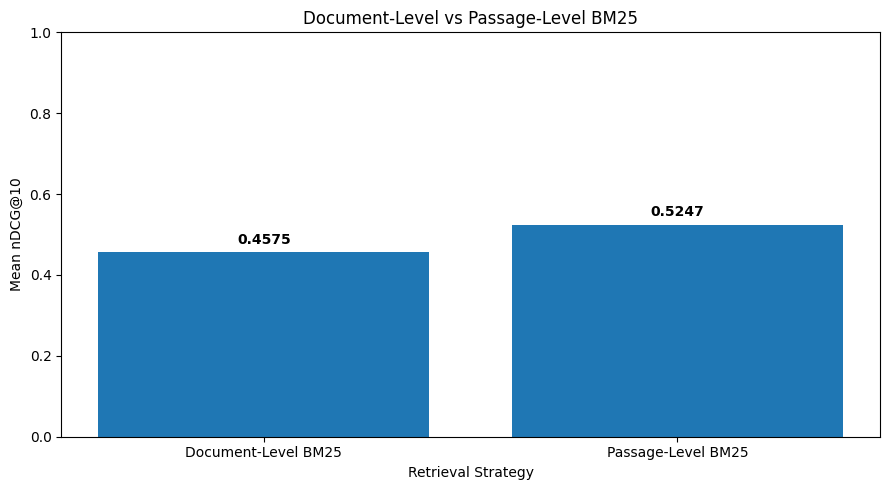

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    chunk_comparison["Retrieval Method"],
    chunk_comparison["Mean nDCG@10"]
)

plt.title("Document-Level vs Passage-Level BM25")
plt.xlabel("Retrieval Strategy")
plt.ylabel("Mean nDCG@10")
plt.ylim(0, 1)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [116]:
# Save passage-level evaluation results
chunk_aggregated_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "chunk_bm25_results.csv"
    ),
    index=False
)

chunk_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "chunk_retrieval_comparison.csv"
    ),
    index=False
)

print("Passage retrieval evaluation results saved!")

Passage retrieval evaluation results saved!


### **9.6 Key Findings & Engineering Considerations**

This experiment introduced overlapping text chunking to improve the granularity of financial document retrieval.

**Key Implementation Highlights**

- Implemented reusable text chunking with overlapping passages.
- Preserved source-document identifiers for evidence traceability.
- Built a BM25 index over financial document chunks.
- Aggregated passage scores into unique document rankings.
- Evaluated retrieval quality against document-level BM25 using nDCG@10.

**Engineering Considerations**

Passage-level retrieval can help locate specific financial disclosures within lengthy reports. However, chunking also introduces additional indexing and search overhead.

The chunking implementation uses approximate word-based limits rather than exact tokenizer lengths. Financial tables and disclosures may also span chunk boundaries.

The measured evaluation results determine whether this approach improves ranking performance on the dataset.

**Next Stage:** Apply cross-encoder reranking to the retrieved passages to improve evidence selection before LLM-based answer generation.

## **10. Cross-Encoder Reranking for Financial Evidence Retrieval**

Retrieval models such as BM25 efficiently identify potentially relevant financial passages. However, their initial ranking may not always place the most useful evidence at the top.

To improve evidence selection, this pipeline introduces a **Cross-Encoder Reranking Model**.

Unlike bi-encoder semantic search, which independently generates embeddings for queries and documents, a cross-encoder processes the financial question and candidate passage together to estimate their relevance.

### **Model Used**

**cross-encoder/ms-marco-MiniLM-L-6-v2**

### **Reranking Workflow**

1. Retrieve the top 50 candidate passages using BM25.
2. Create question–passage pairs.
3. Score each pair using the pretrained cross-encoder.
4. Sort passages by cross-encoder relevance score.
5. Remove duplicate parent documents from the final ranking.
6. Evaluate document rankings using nDCG@10.

The results are compared with document-level BM25 and passage-level BM25 to measure the impact of reranking.

This stage prepares higher-ranked financial evidence for downstream LLM-based question answering.

In [117]:
from sentence_transformers import CrossEncoder
import torch

RERANKER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"

device = "cuda" if torch.cuda.is_available() else "cpu"

reranker = CrossEncoder(
    RERANKER_NAME,
    device=device
)

print("Cross-encoder reranker loaded successfully!")
print("Model:", RERANKER_NAME)
print("Device:", device)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Cross-encoder reranker loaded successfully!
Model: cross-encoder/ms-marco-MiniLM-L-6-v2
Device: cuda


### **10.1 Candidate Passage Generation**

Cross-encoder models provide more detailed relevance scoring but are computationally more expensive than BM25.

To balance retrieval efficiency and ranking quality, the pipeline uses a two-stage architecture.

**Stage 1 — Candidate Retrieval:** BM25 retrieves the top 50 financial passages for each question.

**Stage 2 — Neural Reranking:** The cross-encoder evaluates these candidates using question–passage pairs.

Only queries with available relevance judgments are included in the evaluation.

In [118]:
import numpy as np

TOP_CHUNKS = 50

evaluation_jobs = []
all_pairs = []

for _, row in queries.iterrows():

    query_id = str(row["_id"])
    query_text = str(row["text"])

    # Evaluate only judged queries
    if query_id not in relevance_by_query:
        continue

    # Retrieve candidate passages using BM25
    query_tokens = tokenize(query_text)
    chunk_scores = chunk_bm25.get_scores(query_tokens)

    candidate_indices = np.argsort(chunk_scores)[::-1][:TOP_CHUNKS]

    # Prepare question-passage pairs
    pairs = [
        [query_text, chunks[int(idx)]]
        for idx in candidate_indices
    ]

    all_pairs.extend(pairs)

    evaluation_jobs.append({
        "query_id": query_id,
        "query_text": query_text,
        "relevance": relevance_by_query[query_id],
        "candidate_indices": candidate_indices
    })

print("Candidate generation completed!")
print("Queries to evaluate:", len(evaluation_jobs))
print("Question-passage pairs:", len(all_pairs))

Candidate generation completed!
Queries to evaluate: 344
Question-passage pairs: 17200


### **10.2 Neural Relevance Scoring**

The cross-encoder evaluates each financial question together with its candidate passages.

Unlike cosine similarity, cross-encoder scoring allows the model to consider interactions between the question and passage tokens.

The resulting relevance scores are used to reorder the candidate passages.

Higher scores indicate stronger predicted relevance within the candidate set.

Batch inference is used to process question–passage pairs more efficiently.

In [119]:
from tqdm.auto import tqdm

# Run cross-encoder inference
reranker_scores = reranker.predict(
    all_pairs,
    batch_size=32,
    show_progress_bar=True
)

print("Cross-encoder scoring completed!")
print("Total passages scored:", len(reranker_scores))

Batches:   0%|          | 0/538 [00:00<?, ?it/s]

Cross-encoder scoring completed!
Total passages scored: 17200


### **10.3 Document-Level Ranking After Reranking**

Multiple retrieved passages may belong to the same financial document.

To produce unique document rankings, the pipeline sorts candidate passages by their cross-encoder scores and retains the first occurrence of each parent document.

The resulting top 10 documents are evaluated using nDCG@10 against the available relevance judgments.

This enables a consistent document-level comparison with earlier retrieval experiments.

In [120]:
import pandas as pd
import numpy as np

reranked_results = []
score_offset = 0

for job in evaluation_jobs:

    candidate_indices = job["candidate_indices"]
    num_candidates = len(candidate_indices)

    # Get scores for this query
    scores = reranker_scores[
        score_offset:score_offset + num_candidates
    ]

    score_offset += num_candidates

    # Rank candidate passages
    ranked_positions = np.argsort(scores)[::-1]

    ranked_doc_ids = []
    seen_doc_ids = set()

    for position in ranked_positions:

        chunk_idx = int(candidate_indices[position])
        doc_id = str(parent_doc_ids[chunk_idx])

        if doc_id not in seen_doc_ids:
            ranked_doc_ids.append(doc_id)
            seen_doc_ids.add(doc_id)

        if len(ranked_doc_ids) == 10:
            break

    # Evaluate document ranking
    ndcg = calculate_ndcg_at_k(
        ranked_doc_ids,
        job["relevance"],
        k=10
    )

    reranked_results.append({
        "query_id": job["query_id"],
        "question": job["query_text"],
        "ndcg_at_10": ndcg,
        "retrieved_doc_ids": ranked_doc_ids
    })

reranked_df = pd.DataFrame(reranked_results)

print("Cross-encoder evaluation completed!")
print("Queries evaluated:", len(reranked_df))

print(
    "Mean nDCG@10:",
    round(reranked_df["ndcg_at_10"].mean(), 4)
)

Cross-encoder evaluation completed!
Queries evaluated: 344
Mean nDCG@10: 0.5278


### **10.4 Cross-Encoder Reranking Performance Comparison**

This experiment compares three retrieval configurations:

- **Document-Level BM25:** Keyword retrieval over complete financial documents.
- **Passage-Level BM25:** Keyword retrieval over overlapping passages, followed by document aggregation.
- **BM25 + Cross-Encoder:** Passage retrieval followed by neural relevance scoring and document deduplication.

The comparison measures whether cross-encoder reranking improves nDCG@10 over the baseline methods.

The reranking experiment uses 50 candidate passages per query, while the earlier passage-level BM25 experiment uses 100. Therefore, any measured differences reflect both candidate selection and reranking. A controlled comparison using identical candidate sets would isolate the effect of the cross-encoder.

In [121]:
reranking_comparison = pd.DataFrame({
    "Retrieval Method": [
        "Document-Level BM25",
        "Passage-Level BM25",
        "BM25 + Cross-Encoder"
    ],
    "Mean nDCG@10": [
        bm25_results_df["ndcg_at_10"].mean(),
        chunk_aggregated_df["ndcg_at_10"].mean(),
        reranked_df["ndcg_at_10"].mean()
    ],
    "Queries Evaluated": [
        len(bm25_results_df),
        len(chunk_aggregated_df),
        len(reranked_df)
    ]
})

display(reranking_comparison.round(4))

baseline_score = chunk_aggregated_df["ndcg_at_10"].mean()
reranker_score = reranked_df["ndcg_at_10"].mean()

print(
    f"Difference vs Passage-Level BM25: "
    f"{reranker_score - baseline_score:+.4f}"
)

,Retrieval Method,Mean nDCG@10,Queries Evaluated
0,Document-Level BM25,0.4575,344
1,Passage-Level BM25,0.5247,344
2,BM25 + Cross-Encoder,0.5278,344


Difference vs Passage-Level BM25: +0.0031


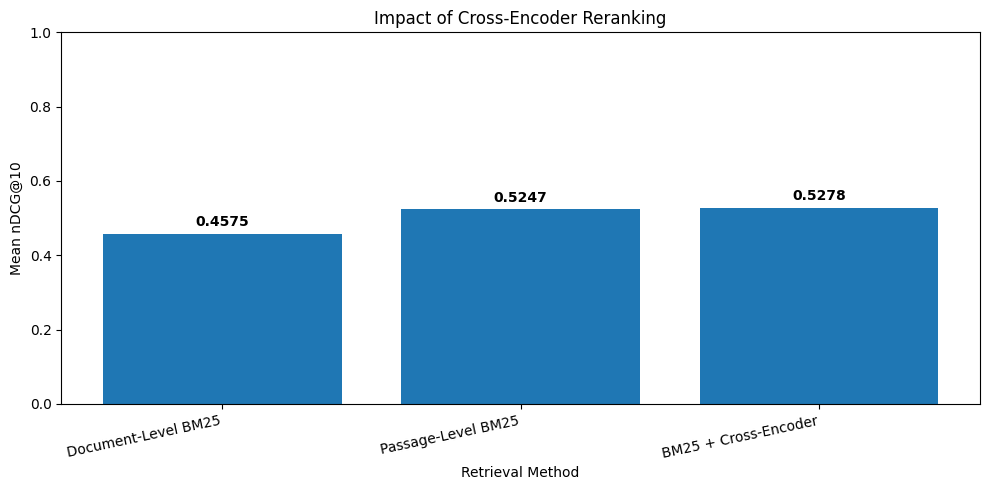

In [122]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    reranking_comparison["Retrieval Method"],
    reranking_comparison["Mean nDCG@10"]
)

plt.title("Impact of Cross-Encoder Reranking")
plt.xlabel("Retrieval Method")
plt.ylabel("Mean nDCG@10")
plt.ylim(0, 1)

plt.xticks(rotation=12, ha="right")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### **10.5 Financial Evidence Reranking Demonstration**

To demonstrate the final evidence-selection process, a sample financial question is passed through the two-stage retrieval pipeline.

BM25 first identifies candidate passages, and the cross-encoder then reorders them according to predicted relevance.

The highest-ranked passages are displayed with their source-document identifiers and reranking scores.

These passages can subsequently be supplied as context to the financial question-answering model.

In [123]:
# Sample financial question
sample_question = queries.iloc[0]["text"]

# BM25 candidate retrieval
scores = chunk_bm25.get_scores(tokenize(sample_question))
candidate_indices = np.argsort(scores)[::-1][:50]

# Prepare question-passage pairs
pairs = [
    [sample_question, chunks[int(idx)]]
    for idx in candidate_indices
]

# Cross-encoder scoring
cross_scores = reranker.predict(
    pairs,
    batch_size=16
)

# Rank passages
top_positions = np.argsort(cross_scores)[::-1][:5]

print("Financial Question:")
print(sample_question)

print("\nTop 5 Reranked Financial Passages\n")

for rank, position in enumerate(top_positions, start=1):

    chunk_idx = int(candidate_indices[position])

    print(f"Rank: {rank}")
    print(f"Document ID: {parent_doc_ids[chunk_idx]}")
    print(f"Chunk ID: {chunk_ids[chunk_idx]}")
    print(f"Cross-Encoder Score: {cross_scores[position]:.4f}")
    print(f"Passage:\n{chunks[chunk_idx][:700]}")
    print("-" * 70)

Financial Question:
what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

Top 5 Reranked Financial Passages

Rank: 1
Document ID: d616769d6
Chunk ID: d616769d6_chunk_2
Cross-Encoder Score: 6.4812
Passage:
incur daily losses greater than those predicted by var esti- mates about twelve times a year . the following table provides information about the sensitivity of dva to a one basis point increase in jpmorgan chase 2019s credit spreads . the sensitivity of dva at december 31 , 2008 , represents the firm ( includ- ing bear stearns ) , while the sensitivity of dva for december 31 , 2007 , represents heritage jpmorgan chase only . debit valuation adjustment sensitivity 1 basis point increase in ( in millions ) jpmorgan chase credit spread . ( in millions ) | 1 basis point increase in jpmorgan chase credit spread ---------------- | ------------------------------------------------------ december 31
---------------------------------

In [124]:
# Save cross-encoder evaluation results
reranked_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "cross_encoder_reranking_results.csv"
    ),
    index=False
)

# Save comparison
reranking_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "reranking_comparison.csv"
    ),
    index=False
)

print("Cross-encoder evaluation results saved!")

Cross-encoder evaluation results saved!


### **10.6 Key Findings & Engineering Considerations**

This stage extends the financial retrieval pipeline with neural reranking.

**Implementation Highlights**

- Implemented two-stage passage retrieval using BM25 and a cross-encoder.
- Generated question–passage pairs for neural relevance scoring.
- Processed candidates using batched model inference.
- Preserved source-document traceability.
- Evaluated the final document rankings using nDCG@10.
- Compared retrieval configurations using measured performance.

**Engineering Considerations**

Cross-encoder reranking provides more detailed query–passage relevance scoring but introduces additional computational cost.

The quality of the final ranking depends on the candidate passages identified during the first retrieval stage.

The evaluation results determine whether reranking provides measurable improvements for this financial dataset.

**Next Stage:** Integrate the retrieved financial evidence with Qwen2.5-3B-Instruct to generate grounded natural-language answers.

## **11. LLM-Based Financial Question Answering**

This section integrates the financial document retrieval pipeline with a Large Language Model (LLM) to generate natural-language answers grounded in financial reports.

The system uses **Qwen2.5-3B-Instruct**, an instruction-tuned language model, together with BM25 passage retrieval and cross-encoder reranking.

### **End-to-End RAG Workflow**

1. Receive a natural-language financial question.
2. Retrieve the top 50 candidate passages using BM25.
3. Rerank candidate passages using a cross-encoder.
4. Select the top five passages as supporting evidence.
5. Construct a prompt containing the financial question and retrieved context.
6. Generate an answer using Qwen2.5-3B-Instruct.
7. Return the generated answer with its supporting document and chunk identifiers.

The model is instructed to use only the retrieved evidence, avoid unsupported financial figures, and explain calculations where possible.

This architecture combines efficient information retrieval with neural reranking and grounded language generation.

### **11.1 Language Model Initialization**

The question-answering system uses **Qwen/Qwen2.5-3B-Instruct**, a pretrained instruction-following language model.

The model is loaded through the Hugging Face Transformers library.

GPU acceleration is used when available, while the model can also run on CPU with sufficient system memory.

The model is used for inference rather than fine-tuning, allowing the system to generate answers directly from retrieved financial evidence.

In [125]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    LLM_MODEL_NAME
)

# Load pretrained language model
llm = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL_NAME,
    torch_dtype=(
        torch.float16
        if torch.cuda.is_available()
        else torch.float32
    ),
    device_map="auto"
)

llm.eval()

print("Financial language model loaded successfully!")
print("Model:", LLM_MODEL_NAME)
print("Device:", next(llm.parameters()).device)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Financial language model loaded successfully!
Model: Qwen/Qwen2.5-3B-Instruct
Device: cuda:0


### **11.2 Financial Evidence Retrieval**

Before generating an answer, the pipeline retrieves supporting information from the financial document collection.

The retrieval process uses two stages:

**Stage 1 — BM25:** Retrieves the top 50 passages based on keyword relevance.

**Stage 2 — Cross-Encoder:** Reranks the retrieved passages based on their relevance to the financial question.

The top five passages are selected as evidence and retain their source-document identifiers, chunk identifiers, and reranking scores.

This separation allows the retrieval component to be tested independently from the language model.

In [126]:
import numpy as np

def retrieve_financial_evidence(
    question,
    top_k_chunks=50,
    top_k_evidence=5
):
    """Retrieve and rerank financial passages."""

    # Stage 1: BM25 candidate retrieval
    query_tokens = tokenize(question)

    chunk_scores = chunk_bm25.get_scores(query_tokens)

    candidate_indices = np.argsort(chunk_scores)[::-1][
        :top_k_chunks
    ]

    # Stage 2: Cross-encoder reranking
    pairs = [
        [question, chunks[int(idx)]]
        for idx in candidate_indices
    ]

    rerank_scores = reranker.predict(
        pairs,
        batch_size=16
    )

    ranked_positions = np.argsort(rerank_scores)[::-1][
        :top_k_evidence
    ]

    # Prepare traceable evidence
    evidence = []

    for rank, position in enumerate(ranked_positions, start=1):

        chunk_idx = int(candidate_indices[position])

        evidence.append({
            "rank": rank,
            "document_id": parent_doc_ids[chunk_idx],
            "chunk_id": chunk_ids[chunk_idx],
            "reranker_score": float(rerank_scores[position]),
            "text": chunks[chunk_idx]
        })

    return evidence


print("Financial evidence retrieval function created!")

Financial evidence retrieval function created!


### **11.3 Evidence-Grounded Prompt Construction**

The retrieved financial passages are formatted into a structured context and supplied to the language model.

The prompt instructs the model to answer using only the supplied evidence, avoid unsupported financial values, and explain calculations when the necessary figures are available.

If the retrieved evidence is insufficient, the model is instructed to acknowledge the limitation rather than invent an answer.

Source-document identifiers are included in the context to support answer traceability.

In [127]:
def build_financial_prompt(question, evidence):
    """Build a grounded financial QA prompt."""

    context = "\n\n".join(
        f"[Evidence {item['rank']} | "
        f"Document {item['document_id']} | "
        f"Chunk {item['chunk_id']}]\n"
        f"{item['text']}"
        for item in evidence
    )

    system_message = (
        "You are a financial question-answering assistant. "
        "Answer using only the provided evidence. "
        "Do not invent facts or unsupported numbers. "
        "For calculations, show the values and formula when possible. "
        "If the evidence is insufficient, clearly say so. "
        "Keep the answer concise and include supporting evidence numbers."
    )

    user_message = (
        f"Evidence:\n{context}\n\n"
        f"Question: {question}"
    )

    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message}
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


print("Financial prompt builder initialized!")

Financial prompt builder initialized!


### **11.4 End-to-End Financial RAG Pipeline**

This function integrates the retrieval, reranking, prompt construction, and language generation components into a single reusable question-answering pipeline.

For each financial question, the system retrieves supporting passages, constructs an evidence-grounded prompt, and generates an answer using Qwen2.5-3B-Instruct.

The function returns both the generated response and the supporting evidence, making it possible to inspect the information used by the language model.

In [128]:
def answer_financial_question(question):
    """
    End-to-end financial RAG pipeline:
    BM25 -> Cross-Encoder -> Qwen -> Answer
    """

    # 1. Retrieve relevant evidence
    evidence = retrieve_financial_evidence(
        question,
        top_k_chunks=50,
        top_k_evidence=5
    )

    if not evidence:
        return {
            "question": question,
            "answer": "No supporting evidence was retrieved.",
            "evidence": []
        }

    # 2. Build grounded prompt
    prompt = build_financial_prompt(question, evidence)

    # 3. Tokenize input
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=4096
    )

    model_device = next(llm.parameters()).device

    inputs = {
        key: value.to(model_device)
        for key, value in inputs.items()
    }

    # 4. Generate answer
    with torch.no_grad():
        output = llm.generate(
            **inputs,
            max_new_tokens=250,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # 5. Decode generated answer
    generated_tokens = output[0][
        inputs["input_ids"].shape[1]:
    ]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    # 6. Return answer and evidence
    return {
        "question": question,
        "answer": answer,
        "evidence": evidence
    }


print("End-to-end Financial RAG Pipeline initialized!")

End-to-end Financial RAG Pipeline initialized!


### **11.5 Financial Question Answering Demonstration**

A sample question from the financial dataset is submitted to the complete RAG pipeline.

The system retrieves relevant financial passages, reranks them, and generates a natural-language response.

The demonstration displays the financial question, generated answer, and supporting document references.

This illustrates the complete workflow from natural-language input to evidence-grounded answer generation.

In [129]:
# Select a sample financial question
sample_question = queries.iloc[0]["text"]

# Generate answer
result = answer_financial_question(sample_question)

print("=" * 70)
print("FINANCIAL QUESTION")
print("=" * 70)
print(result["question"])

print("\n" + "=" * 70)
print("GENERATED ANSWER")
print("=" * 70)
print(result["answer"])

print("\n" + "=" * 70)
print("SUPPORTING EVIDENCE")
print("=" * 70)

for item in result["evidence"]:
    print(f"\nEvidence {item['rank']}")
    print("Document:", item["document_id"])
    print("Chunk:", item["chunk_id"])
    print("Reranker Score:", round(item["reranker_score"], 4))
    print("Text:", item["text"][:350])
    print("-" * 60)

FINANCIAL QUESTION
what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

GENERATED ANSWER
To find the average impact on DVA of a 1 basis point increase in JPMorgan Chase's credit spread for 2008 and 2007:

1. From Evidence 1, we see the DVA sensitivity for December 31, 2008 is $32 million.
2. From Evidence 1, we also see the DVA sensitivity for December 31, 2007 is $38 million.
3. To calculate the average, sum these two values and divide by 2:
   (32 + 38) / 2 = 70 / 2 = 35

The average impact on DVA of a 1 basis point increase in JPMorgan Chase's credit spread for 2008 and 2007 was $35 million.

SUPPORTING EVIDENCE

Evidence 1
Document: d616769d6
Chunk: d616769d6_chunk_2
Reranker Score: 6.4812
Text: incur daily losses greater than those predicted by var esti- mates about twelve times a year . the following table provides information about the sensitivity of dva to a one basis point increase in jpmorgan chase 2019s credit spr

In [130]:
from IPython.display import display, Markdown
import pandas as pd

# Display financial question and answer
display(Markdown(
    "### Financial Question\n\n"
    + result["question"]
))

display(Markdown(
    "### Generated Answer\n\n"
    + result["answer"]
))

# Display supporting evidence
evidence_df = pd.DataFrame([
    {
        "Rank": item["rank"],
        "Document ID": item["document_id"],
        "Chunk ID": item["chunk_id"],
        "Reranker Score": round(item["reranker_score"], 4),
        "Evidence Preview": item["text"][:200]
    }
    for item in result["evidence"]
])

display(evidence_df)

### Financial Question

what was the average impact on dva of a 1 basis point increase in jpmorgan chase credit spread for 2008 and 2007?

### Generated Answer

To find the average impact on DVA of a 1 basis point increase in JPMorgan Chase's credit spread for 2008 and 2007:

1. From Evidence 1, we see the DVA sensitivity for December 31, 2008 is $32 million.
2. From Evidence 1, we also see the DVA sensitivity for December 31, 2007 is $38 million.
3. To calculate the average, sum these two values and divide by 2:
   (32 + 38) / 2 = 70 / 2 = 35

The average impact on DVA of a 1 basis point increase in JPMorgan Chase's credit spread for 2008 and 2007 was $35 million.

,Rank,Document ID,Chunk ID,Reranker Score,Evidence Preview
0,1,d616769d6,d616769d6_chunk_2,6.4812,incur daily losses greater than those predicte...
1,2,d61d2a890,d61d2a890_chunk_4,5.4449,the following table provides information about...
2,3,d61d2c15e,d61d2c15e_chunk_2,5.1818,table provides information about the gross sen...
3,4,d61d31046,d61d31046_chunk_1,4.6624,exceeded the var measure on one day due to hig...
4,5,d61d31046,d61d31046_chunk_2,3.9534,change in spreads at a single maturity point m...


In [131]:
import json
import os

# Save generated answer and supporting evidence
output_file = os.path.join(
    OUTPUT_DIR,
    "financial_rag_demo.json"
)

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(
        result,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Financial RAG demonstration saved!")

Financial RAG demonstration saved!


### **11.6 Implementation Summary**

The financial question-answering pipeline integrates three core components:

**1. Information Retrieval**

BM25 efficiently identifies candidate financial passages based on the user's question.

**2. Neural Reranking**

A cross-encoder evaluates the retrieved passages and selects the highest-ranked evidence for answer generation.

**3. Large Language Model**

Qwen2.5-3B-Instruct generates a natural-language response using the retrieved financial context.

### **Key Engineering Features**

- Modular retrieval and answer-generation functions.
- Two-stage evidence selection.
- Source-document and chunk-level traceability.
- Evidence-grounded prompt construction.
- Deterministic decoding configuration.
- Structured output containing answers and supporting evidence.

### **Limitations**

The model may still produce incorrect answers or calculations despite evidence-grounded prompting.

Retrieval quality depends on the completeness of the source documents and the relevance of selected passages.

Long prompts may be truncated to fit the configured input limit, potentially removing useful evidence.

The next stage introduces numerical validation to check financial calculations independently of the language model.

## 12. **Financial Evidence Extraction & Calculation Validation**

Financial questions frequently require numerical calculations based on figures reported in annual reports and financial statements.

Although the RAG pipeline can generate natural-language answers using Qwen2.5, numerical accuracy requires additional verification.

This project extends the retrieval pipeline with **rule-based financial value extraction and deterministic calculations**.

### **Validation Workflow**

1. Retrieve relevant financial evidence using BM25 and cross-encoder reranking.
2. Identify financial figures using regular-expression-based extraction.
3. Perform calculations using Python.
4. Generate an answer containing the extracted figures and calculated result.
5. Preserve source-document and passage identifiers.
6. Return an explicit status when sufficient evidence is unavailable.

### **Financial Scenarios**

The implementation covers environmental reserves, tax credit investments, employee stock purchase plans (ESPP), aircraft fuel expenses, share repurchases, and NPM adjustment items.

These are question-specific validation workflows rather than a general-purpose financial calculation engine. Their accuracy depends on correctly extracting the relevant values from source documents.

### **12.1 Deterministic Financial Calculations**

The calculation engine supports three common financial operations:

- Percentage of total: `(numerator / denominator) × 100`
- Percentage change: `((new value − old value) / |old value|) × 100`
- Absolute change: `new value − old value`

Using Python for arithmetic reduces reliance on the language model's ability to calculate numerical results.

The implementation also checks for zero denominators and unsupported calculation types.

In [132]:
def calculate_financial_value(question_type, values):

    if question_type == "percentage_of_total":
        numerator = values["numerator"]
        denominator = values["denominator"]

        if denominator == 0:
            raise ValueError("Denominator cannot be zero.")

        return round((numerator / denominator) * 100, 2)

    elif question_type == "percentage_change":
        old_value = values["old_value"]
        new_value = values["new_value"]

        if old_value == 0:
            raise ValueError("Old value cannot be zero.")

        return round(
            ((new_value - old_value) / abs(old_value)) * 100,
            2
        )

    elif question_type == "absolute_change":
        return round(
            values["new_value"] - values["old_value"],
            4
        )

    else:
        raise ValueError("Unsupported question type.")


print("Financial calculation engine initialized!")

Financial calculation engine initialized!


### **12.2 Financial Validation Test Cases**

Six financial questions from the original project are used to demonstrate numerical evidence extraction and calculation.

The test cases cover different financial reporting formats, including narrative disclosures and financial tables.

The objective is to determine whether the system can locate the required numerical values, perform the appropriate calculation, and return an answer with supporting source information.

In [133]:
validation_questions = {
    "environmental": (
        "Considering the year 2015, what is the percentage "
        "of reserves for environmental matters related "
        "to remediation of sites?"
    ),
    "tax_credit": (
        "For tax credit investments included in our equity "
        "investments held by consolidated partnerships, "
        "what was the change in billions between "
        "December 31, 2013 and December 31, 2014?"
    ),
    "shares": (
        "What percentage of total number of shares "
        "purchased were repurchased in open-market transactions?"
    ),
    "espp": (
        "What was the percentage change in the weighted "
        "average fair value for the ESPP shares purchased "
        "from 2007 to 2005?"
    ),
    "fuel": (
        "What is the percentage change in total cost "
        "of aircraft fuel in 2013?"
    ),
    "npm": (
        "What are the NPM adjustment items as a percentage "
        "of the operating companies income increase?"
    )
}

for name, question in validation_questions.items():
    print(f"{name.upper()}: {question}\n")

ENVIRONMENTAL: Considering the year 2015, what is the percentage of reserves for environmental matters related to remediation of sites?

TAX_CREDIT: For tax credit investments included in our equity investments held by consolidated partnerships, what was the change in billions between December 31, 2013 and December 31, 2014?

SHARES: What percentage of total number of shares purchased were repurchased in open-market transactions?

ESPP: What was the percentage change in the weighted average fair value for the ESPP shares purchased from 2007 to 2005?

FUEL: What is the percentage change in total cost of aircraft fuel in 2013?

NPM: What are the NPM adjustment items as a percentage of the operating companies income increase?



### 12.3 Evidence Retrieval for Numerical Validation

The validation pipeline uses the passage retrieval and cross-encoder reranking components developed in earlier sections.

For each financial question, the system retrieves relevant passages and preserves their source-document identifiers.

These passages are examined for the specific financial values required by the calculation.

Some financial tables may not be fully represented within individual chunks. The original implementation also includes document-level fallback logic for selected cases.

In [134]:
# Reuse the retrieval function from Section 11
validation_evidence = {}

for name, question in validation_questions.items():

    evidence = retrieve_financial_evidence(
        question,
        top_k_chunks=50,
        top_k_evidence=5
    )

    validation_evidence[name] = evidence

    print(
        f"{name}: {len(evidence)} evidence passages retrieved"
    )

environmental: 5 evidence passages retrieved
tax_credit: 5 evidence passages retrieved
shares: 5 evidence passages retrieved
espp: 5 evidence passages retrieved
fuel: 5 evidence passages retrieved
npm: 5 evidence passages retrieved


### **12.4 Financial Value Extraction**

Financial reports contain values in different formats, including narrative disclosures, multi-year comparisons, and structured tables.

The pipeline implements scenario-specific regular expressions to identify the numerical values required for each question.

The extraction functions return structured dictionaries containing the values and relevant reporting years.

If the expected pattern is not found, the extractor returns `None` rather than inventing financial figures.

In [135]:
import re

def extract_environmental_reserves(text):
    pattern = (
        r"as of december 31\s*,?\s*(\d{4})\s+and\s+(\d{4})"
        r".*?reserves for environmental matters of"
        r"\s*\$\s*([\d.]+)\s*million\s+and\s+"
        r"\$\s*([\d.]+)\s*million"
        r".*?of these amounts"
        r"\s*\$\s*([\d.]+)\s*million\s+and\s+"
        r"\$\s*([\d.]+)\s*million"
    )

    match = re.search(
        pattern, text, re.IGNORECASE | re.DOTALL
    )

    if not match:
        return None

    y1, y2, t1, t2, r1, r2 = match.groups()

    return {
        y1: {
            "total_reserves": float(t1),
            "remediation_reserves": float(r1)
        },
        y2: {
            "total_reserves": float(t2),
            "remediation_reserves": float(r2)
        }
    }


def extract_tax_credit_values(text):
    pattern = (
        r"tax credit investments\s*\(\s*a\s*\)\s*\|\s*"
        r"(\d+)\s*\|\s*(\d+)"
    )

    match = re.search(pattern, text, re.IGNORECASE)

    if not match:
        return None

    return {
        "2014": float(match.group(1)),
        "2013": float(match.group(2)),
        "unit": "million"
    }


def extract_espp_values(text):
    pattern = (
        r"weighted average fair value for the espp shares purchased "
        r"during\s+(\d{4})\s*,?\s*(\d{4})\s+and\s+(\d{4})\s+"
        r"were\s*\$\s*([\d.]+)\s*,?\s*"
        r"\$\s*([\d.]+)\s+and\s+\$\s*([\d.]+)"
    )

    match = re.search(pattern, text, re.IGNORECASE)

    if not match:
        return None

    y1, y2, y3, v1, v2, v3 = match.groups()

    return {
        y1: float(v1),
        y2: float(v2),
        y3: float(v3)
    }


def extract_fuel_cost_values(text):
    pattern = (
        r"2012\s*\|\s*\d+\s*\|\s*\$\s*[\d.]+\s*\|\s*\$\s*([\d,]+)"
        r".*?"
        r"2013\s*\|\s*\d+\s*\|\s*\$\s*[\d.]+\s*\|\s*\$\s*([\d,]+)"
    )

    match = re.search(
        pattern, text, re.IGNORECASE | re.DOTALL
    )

    if not match:
        return None

    return {
        "2012": float(match.group(1).replace(",", "")),
        "2013": float(match.group(2).replace(",", "")),
        "unit": "million"
    }


def extract_share_repurchase_values(text):
    total = re.search(
        r"total\s*:\s*\|\s*([\d,]+)",
        text,
        re.IGNORECASE
    )

    market = re.search(
        r"([\d,]+)\s+shares were repurchased in open-market transactions",
        text,
        re.IGNORECASE
    )

    if not total or not market:
        return None

    return {
        "total_shares": float(total.group(1).replace(",", "")),
        "open_market_shares": float(
            market.group(1).replace(",", "")
        )
    }


def extract_npm_values(text):
    income = re.search(
        r"operating companies income increased\s+\$\s*([\d,]+)\s+million",
        text,
        re.IGNORECASE
    )

    npm = re.search(
        r"npm adjustment items\s*\(\s*\$\s*([\d,]+)\s+million\s*\)",
        text,
        re.IGNORECASE
    )

    if not income or not npm:
        return None

    return {
        "income_increase": float(
            income.group(1).replace(",", "")
        ),
        "npm_adjustment_items": float(
            npm.group(1).replace(",", "")
        ),
        "unit": "million"
    }


print("Six financial value extractors initialized!")

Six financial value extractors initialized!


### **12.5 Evidence-Based Financial Answer Generation**

Each financial scenario has its own extraction and calculation requirements.

The validation function searches retrieved passages for the expected financial values and performs the appropriate calculation.

For the tax credit and aircraft fuel scenarios, the implementation can also inspect the original source document when the relevant table is missing from the retrieved chunks.

The output includes a calculation result, formatted answer, source-document identifier, and execution status.

A successful status indicates that the expected values were extracted and the calculation completed. It does not independently establish that the extracted figures match the correct financial disclosure.

In [136]:
def has_required_years(scenario, values):
    required_years = {
        "environmental": {"2015"},
        "espp": {"2005", "2007"},
        "tax_credit": {"2013", "2014"},
        "fuel": {"2012", "2013"}
    }

    return required_years.get(scenario, set()).issubset(
        values.keys()
    )

In [137]:
extractors = {
    "environmental": extract_environmental_reserves,
    "tax_credit": extract_tax_credit_values,
    "shares": extract_share_repurchase_values,
    "espp": extract_espp_values,
    "fuel": extract_fuel_cost_values,
    "npm": extract_npm_values
}

# Original notebook's identified source documents
fallback_document_ids = {
    "tax_credit": "d6165ab96",
    "fuel": "d6167e6f4"
}


def find_financial_values(scenario, evidence):

    extractor = extractors[scenario]

    # First: search the top reranked evidence passages
    for item in evidence:

        values = extractor(item["text"])

        if values is not None and has_required_years(
            scenario, values
        ):
            return {
                "values": values,
                "document_id": item["document_id"],
                "chunk_id": item["chunk_id"],
                "rank": item["rank"],
                "source_type": "retrieved_passage"
            }

    # Second: search more passages using BM25
    question = validation_questions[scenario]

    scores = chunk_bm25.get_scores(tokenize(question))

    candidate_indices = np.argsort(scores)[::-1][:500]

    for idx in candidate_indices:

        idx = int(idx)
        values = extractor(chunks[idx])

        if values is not None and has_required_years(
            scenario, values
        ):
            return {
                "values": values,
                "document_id": parent_doc_ids[idx],
                "chunk_id": chunk_ids[idx],
                "rank": None,
                "source_type": "expanded_bm25_search"
            }

    # Third: search the full corpus if passages fail
    for _, row in corpus.iterrows():

        values = extractor(str(row["text"]))

        if values is not None and has_required_years(
            scenario, values
        ):
            return {
                "values": values,
                "document_id": str(row["_id"]),
                "chunk_id": None,
                "rank": None,
                "source_type": "full_corpus_fallback"
            }

    return None


def calculate_scenario_answer(scenario, values):

    if scenario == "environmental":
        data = values["2015"]

        result = calculate_financial_value(
            "percentage_of_total",
            {
                "numerator": data["remediation_reserves"],
                "denominator": data["total_reserves"]
            }
        )

        answer = (
            f"In 2015, remediation reserves represented "
            f"{result:.2f}% of total environmental reserves."
        )

    elif scenario == "tax_credit":
        result = calculate_financial_value(
            "absolute_change",
            {
                "old_value": values["2013"],
                "new_value": values["2014"]
            }
        )

        answer = (
            f"Tax credit investments changed by "
            f"${result / 1000:.3f} billion "
            f"between 2013 and 2014."
        )

    elif scenario == "shares":
        result = calculate_financial_value(
            "percentage_of_total",
            {
                "numerator": values["open_market_shares"],
                "denominator": values["total_shares"]
            }
        )

        answer = (
            f"Open-market repurchases represented "
            f"{result:.2f}% of total shares purchased."
        )

    elif scenario == "espp":
        result = calculate_financial_value(
            "percentage_change",
            {
                "old_value": values["2005"],
                "new_value": values["2007"]
            }
        )

        answer = (
            f"The weighted average fair value of ESPP "
            f"shares changed by {result:.2f}% "
            f"from 2005 to 2007."
        )

    elif scenario == "fuel":
        result = calculate_financial_value(
            "percentage_change",
            {
                "old_value": values["2012"],
                "new_value": values["2013"]
            }
        )

        answer = (
            f"Total aircraft fuel cost changed by "
            f"{result:.2f}% from 2012 to 2013."
        )

    elif scenario == "npm":
        result = calculate_financial_value(
            "percentage_of_total",
            {
                "numerator": values["npm_adjustment_items"],
                "denominator": values["income_increase"]
            }
        )

        answer = (
            f"NPM adjustment items represented "
            f"{result:.2f}% of the increase in "
            f"operating companies income."
        )

    return result, answer


def validate_financial_scenario(scenario, question, evidence):

    selected = find_financial_values(
        scenario,
        evidence
    )

    if selected is None:
        return {
            "scenario": scenario,
            "question": question,
            "status": "INSUFFICIENT_EVIDENCE",
            "answer": None,
            "calculated_value": None,
            "evidence": None
        }

    try:
        value, answer = calculate_scenario_answer(
            scenario,
            selected["values"]
        )

    except (KeyError, ValueError, ZeroDivisionError) as error:
        return {
            "scenario": scenario,
            "question": question,
            "status": "CALCULATION_ERROR",
            "answer": str(error),
            "calculated_value": None,
            "evidence": selected
        }

    return {
        "scenario": scenario,
        "question": question,
        "status": "SUCCESS",
        "answer": answer,
        "calculated_value": value,
        "extracted_values": selected["values"],
        "evidence": {
            "document_id": selected["document_id"],
            "chunk_id": selected["chunk_id"],
            "rank": selected["rank"],
            "source_type": selected["source_type"]
        }
    }


print("Financial scenario validation initialized!")

Financial scenario validation initialized!


### **12.6 Financial Validation Results**

The six financial scenarios are processed using the evidence extraction and calculation pipeline.

Each result includes an execution status, calculated answer, and supporting document information.

The following statuses are used:

**SUCCESS:** Required values were extracted and the calculation completed.

**INSUFFICIENT_EVIDENCE:** The expected financial figures could not be extracted from the available evidence.

**CALCULATION_ERROR:** The extracted data could not be used to complete the calculation.

These statuses measure the behavior of the validation workflow, not independently verified answer accuracy.

In [138]:
for scenario in ["environmental", "espp"]:
    selected = find_financial_values(
        scenario,
        validation_evidence[scenario]
    )

    print("\nScenario:", scenario)

    if selected:
        print("Extracted values:", selected["values"])
        print("Source document:", selected["document_id"])
    else:
        print("No matching financial values found.")


Scenario: environmental
Extracted values: {'2015': {'total_reserves': 15.2, 'remediation_reserves': 2.8}, '2014': {'total_reserves': 8.8, 'remediation_reserves': 2.4}}
Source document: d61693e8c

Scenario: espp
Extracted values: {'2007': 9.09, '2006': 6.79, '2005': 5.15}
Source document: d6168ab98


In [139]:
validated_answers = {}

for scenario, question in validation_questions.items():

    result = validate_financial_scenario(
        scenario,
        question,
        validation_evidence[scenario]
    )

    validated_answers[scenario] = result

    print("=" * 70)
    print("SCENARIO:", scenario.upper())
    print("QUESTION:", question)
    print("STATUS:", result["status"])
    print("ANSWER:", result["answer"])

    if result["evidence"]:
        print(
            "SOURCE DOCUMENT:",
            result["evidence"]["document_id"]
        )
        print(
            "SOURCE TYPE:",
            result["evidence"]["source_type"]
        )

print("=" * 70)
print(
    "Successful scenarios:",
    sum(
        r["status"] == "SUCCESS"
        for r in validated_answers.values()
    ),
    "/",
    len(validated_answers)
)

SCENARIO: ENVIRONMENTAL
QUESTION: Considering the year 2015, what is the percentage of reserves for environmental matters related to remediation of sites?
STATUS: SUCCESS
ANSWER: In 2015, remediation reserves represented 18.42% of total environmental reserves.
SOURCE DOCUMENT: d61693e8c
SOURCE TYPE: retrieved_passage
SCENARIO: TAX_CREDIT
QUESTION: For tax credit investments included in our equity investments held by consolidated partnerships, what was the change in billions between December 31, 2013 and December 31, 2014?
STATUS: SUCCESS
ANSWER: Tax credit investments changed by $0.044 billion between 2013 and 2014.
SOURCE DOCUMENT: d6165ab96
SOURCE TYPE: expanded_bm25_search
SCENARIO: SHARES
QUESTION: What percentage of total number of shares purchased were repurchased in open-market transactions?
STATUS: SUCCESS
ANSWER: Open-market repurchases represented 93.57% of total shares purchased.
SOURCE DOCUMENT: d61657cac
SOURCE TYPE: retrieved_passage
SCENARIO: ESPP
QUESTION: What was the 

In [140]:
import pandas as pd
import os

validation_df = pd.DataFrame([
    {
        "Scenario": scenario,
        "Question": result["question"],
        "Status": result["status"],
        "Calculated Value": result["calculated_value"],
        "Answer": result["answer"],
        "Document ID": (
            result["evidence"]["document_id"]
            if result["evidence"] else None
        ),
        "Chunk ID": (
            result["evidence"]["chunk_id"]
            if result["evidence"] else None
        ),
        "Source Type": (
            result["evidence"]["source_type"]
            if result["evidence"] else None
        )
    }
    for scenario, result in validated_answers.items()
])

display(validation_df)

validation_path = os.path.join(
    OUTPUT_DIR,
    "unified_validation_results.csv"
)

validation_df.to_csv(
    validation_path,
    index=False
)

print("Saved to:", validation_path)

,Scenario,Question,Status,Calculated Value,Answer,Document ID,Chunk ID,Source Type
0,environmental,"Considering the year 2015, what is the percent...",SUCCESS,18.42,"In 2015, remediation reserves represented 18.4...",d61693e8c,d61693e8c_chunk_5,retrieved_passage
1,tax_credit,For tax credit investments included in our equ...,SUCCESS,44.00,Tax credit investments changed by $0.044 billi...,d6165ab96,d6165ab96_chunk_2,expanded_bm25_search
2,shares,What percentage of total number of shares purc...,SUCCESS,93.57,Open-market repurchases represented 93.57% of ...,d61657cac,d61657cac_chunk_5,retrieved_passage
3,espp,What was the percentage change in the weighted...,SUCCESS,76.50,The weighted average fair value of ESPP shares...,d6168ab98,d6168ab98_chunk_6,retrieved_passage
4,fuel,What is the percentage change in total cost of...,SUCCESS,2.78,Total aircraft fuel cost changed by 2.78% from...,d6167e6f4,d6167e6f4_chunk_1,expanded_bm25_search
5,npm,What are the NPM adjustment items as a percent...,SUCCESS,80.58,NPM adjustment items represented 80.58% of the...,d6167743a,d6167743a_chunk_4,retrieved_passage


Saved to: /content/drive/My Drive/Finrag/results/unified_validation_results.csv


### **12.7 Key Findings & Project Limitations**

This stage extends the financial RAG pipeline with numerical evidence extraction and deterministic calculation logic.

**Implementation Highlights**

- Implemented six scenario-specific financial value extractors.
- Supported percentage-of-total, percentage-change, and absolute-change calculations.
- Integrated financial calculations with retrieved document evidence.
- Preserved source-document and passage identifiers.
- Added full-document evidence fallback for selected financial tables.
- Generated structured results for six financial validation scenarios.

**Limitations**

The extraction patterns are designed for specific financial disclosure formats and may not generalize to different companies or report structures.

Some calculations require full-document fallback because relevant table values may be split across passages.

A successful calculation does not guarantee that the correct source values were extracted. Independent comparison with reference answers is still needed to establish end-to-end numerical accuracy.

**Conclusion**

The project demonstrates a financial RAG system that combines information retrieval, neural reranking, language-model generation, financial value extraction, and deterministic numerical calculations.

The implementation provides a foundation for more reliable financial question answering and future automated answer verification.